# Dynamic Supply Chain & Logistics — Exploratory Data Analysis

**Dataset:** `dynamic_supply_chain_logistics_dataset.csv`  
**Coverage described by the provider:** Southern California logistics network, January 2021–January 2024  
**Records in the uploaded file:** verified during execution below.

## Project objective
Explore operational efficiency, shipment delays, supplier and inventory dynamics, cargo condition, route risk, costs, and temporal patterns. The analysis follows the business questions supplied with the dataset and ends with evidence-based recommendations.

## Important interpretation notes
- The supplied file is treated as the source of truth. The notebook checks actual data types, ranges, missing values, duplicates, and timestamp coverage before analysis.
- Several fields described as binary or bounded scores may not actually contain only 0/1 or values in the stated ranges. The notebook reports what is present rather than silently converting or clipping values.
- `order_fulfillment_status` is described as 0/1, but the uploaded file may contain continuous values. A threshold-based rate is shown only as a clearly labelled proxy if values are not binary; it is **not** presented as a verified on-time fulfillment rate.
- Correlation and association do not establish causation. The dataset description does not document a sampling design or a causal experiment.
- The suggested `fuel_efficiency_ratio` is calculated as shipping cost divided by fuel-consumption rate, as requested. It is a cost-to-rate ratio, not a physical fuel-efficiency measure.
- All conclusions must be interpreted in light of the dataset's provenance and quality checks.

## 1. Setup and imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
except ImportError:
    sns = None
    plt.style.use("default")

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the dataset

Place the CSV in the same folder as this notebook (recommended for GitHub). The fallback path supports the original uploaded-file environment.

In [2]:
DATA_FILE = Path("dynamic_supply_chain_logistics_dataset.csv")
if not DATA_FILE.exists():
    fallback = Path("/mnt/data/dynamic_supply_chain_logistics_dataset.csv")
    if fallback.exists():
        DATA_FILE = fallback
    else:
        raise FileNotFoundError(
            "Dataset not found. Place dynamic_supply_chain_logistics_dataset.csv "
            "in the same folder as this notebook."
        )

df = pd.read_csv(DATA_FILE)
print(f"Dataset loaded: {DATA_FILE}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: dynamic_supply_chain_logistics_dataset.csv
Shape: 32,065 rows × 26 columns


,timestamp,vehicle_gps_latitude,vehicle_gps_longitude,fuel_consumption_rate,eta_variation_hours,traffic_congestion_level,warehouse_inventory_level,loading_unloading_time,handling_equipment_availability,order_fulfillment_status,weather_condition_severity,port_congestion_level,shipping_costs,supplier_reliability_score,lead_time_days,historical_demand,iot_temperature,cargo_condition_status,route_risk_level,customs_clearance_time,driver_behavior_score,fatigue_monitoring_score,disruption_likelihood_score,delay_probability,risk_classification,delivery_time_deviation
0,2021-01-01 00:00:00,40.376,-77.014,5.137,4.998,5.928,985.717,4.951,0.481,0.761,0.359,4.289,456.504,0.986,2.128,100.773,0.574,0.777,1.182,0.502,0.034,0.979,0.506,0.885,Moderate Risk,9.111
1,2021-01-01 01:00:00,33.508,-117.037,5.102,0.985,1.592,396.700,1.030,0.621,0.197,0.231,7.018,640.408,0.463,12.608,"5,313.738",-9.753,0.092,9.612,0.967,0.202,0.919,0.981,0.544,High Risk,8.175
2,2021-01-01 02:00:00,30.021,-75.269,5.091,4.973,8.788,832.409,4.220,0.811,0.153,0.027,9.605,155.749,0.599,14.124,"1,595.049",-6.491,0.254,6.570,0.946,0.264,0.394,0.999,0.803,High Risk,1.284
3,2021-01-01 03:00:00,36.649,-70.191,8.220,3.095,0.045,0.573,0.530,0.009,0.812,0.617,8.900,104.318,0.743,3.819,"2,530.432",-0.151,0.878,0.549,4.674,0.363,0.905,0.993,0.026,High Risk,9.305
4,2021-01-01 04:00:00,30.001,-70.012,5.000,3.216,8.005,914.925,3.621,0.020,0.054,0.952,0.062,977.223,0.431,14.001,"2,146.190",2.429,0.262,8.861,3.445,0.017,0.259,0.912,0.991,High Risk,7.752


## 3. Initial data understanding

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Column names:
['timestamp', 'vehicle_gps_latitude', 'vehicle_gps_longitude', 'fuel_consumption_rate', 'eta_variation_hours', 'traffic_congestion_level', 'warehouse_inventory_level', 'loading_unloading_time', 'handling_equipment_availability', 'order_fulfillment_status', 'weather_condition_severity', 'port_congestion_level', 'shipping_costs', 'supplier_reliability_score', 'lead_time_days', 'historical_demand', 'iot_temperature', 'cargo_condition_status', 'route_risk_level', 'customs_clearance_time', 'driver_behavior_score', 'fatigue_monitoring_score', 'disruption_likelihood_score', 'delay_probability', 'risk_classification', 'delivery_time_deviation']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32065 entries, 0 to 32064
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   timestamp                        32065 non-null  object 
 1   vehicle_

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
timestamp,32065,32065,2021-01-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_gps_latitude,"32,065.000",NaN,NaN,NaN,38.024,6.918,30.000,31.281,36.414,44.454,50.000
vehicle_gps_longitude,"32,065.000",NaN,NaN,NaN,-90.117,17.369,-120.000,-106.254,-86.293,-73.079,-70.000
fuel_consumption_rate,"32,065.000",NaN,NaN,NaN,8.012,4.265,5.000,5.020,5.636,9.670,20.000
eta_variation_hours,"32,065.000",NaN,NaN,NaN,2.893,2.274,-2.000,1.186,3.882,4.884,5.000
traffic_congestion_level,"32,065.000",NaN,NaN,NaN,4.991,3.532,0.000,1.475,4.981,8.535,10.000
warehouse_inventory_level,"32,065.000",NaN,NaN,NaN,299.255,323.444,0.000,16.052,157.288,540.598,999.999
loading_unloading_time,"32,065.000",NaN,NaN,NaN,2.292,1.554,0.500,0.775,1.917,3.734,5.000
handling_equipment_availability,"32,065.000",NaN,NaN,NaN,0.303,0.326,0.000,0.017,0.160,0.554,1.000
order_fulfillment_status,"32,065.000",NaN,NaN,NaN,0.601,0.346,0.000,0.277,0.681,0.938,1.000


## 4. Data quality assessment

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

# Parse timestamps without changing the original dataframe column in place.
timestamp = pd.to_datetime(df["timestamp"], errors="coerce")
print("Invalid timestamps:", int(timestamp.isna().sum()))
if timestamp.notna().any():
    print("Timestamp range:", timestamp.min(), "to", timestamp.max())
    print("Distinct calendar dates:", timestamp.dt.date.nunique())

# Check expected binary and bounded fields against the values actually present.
expected_binary = ["handling_equipment_availability", "order_fulfillment_status", "cargo_condition_status"]
binary_checks = []
for col in expected_binary:
    vals = sorted(pd.Series(df[col].dropna().unique()).tolist())
    binary_checks.append({"column": col, "unique_count": len(vals), "min": df[col].min(), "max": df[col].max(), "only_0_or_1": bool(df[col].dropna().isin([0, 1]).all()), "sample_unique_values": vals[:10]})
display(pd.DataFrame(binary_checks))

bounded_checks = {
    "traffic_congestion_level": (0, 10), "port_congestion_level": (0, 10),
    "weather_condition_severity": (0, 1), "supplier_reliability_score": (0, 1),
    "driver_behavior_score": (0, 1), "fatigue_monitoring_score": (0, 1),
    "disruption_likelihood_score": (0, 1), "delay_probability": (0, 1),
    "route_risk_level": (0, 10)
}
range_rows = []
for col, (lo, hi) in bounded_checks.items():
    range_rows.append({"column": col, "expected_min": lo, "expected_max": hi, "actual_min": df[col].min(), "actual_max": df[col].max(), "out_of_range_count": int(((df[col] < lo) | (df[col] > hi)).sum())})
display(pd.DataFrame(range_rows))

# Geographic sanity check against the stated Southern California coverage.
lat_min, lat_max = df["vehicle_gps_latitude"].min(), df["vehicle_gps_latitude"].max()
lon_min, lon_max = df["vehicle_gps_longitude"].min(), df["vehicle_gps_longitude"].max()
print(f"GPS latitude range: {lat_min:.3f} to {lat_max:.3f}")
print(f"GPS longitude range: {lon_min:.3f} to {lon_max:.3f}")
print("Geographic validation: the coordinate span is much broader than Southern California; verify GPS generation/anonymization before mapping routes.")

# Compare actual timestamps with the date range stated in the dataset description.
print("Actual final timestamp:", timestamp.max())
print("Dataset description says coverage ends January 2024; the uploaded file should be checked for any later dates.")

,dtype,missing_count,missing_percent,unique_values
timestamp,object,0,0.000,32065
vehicle_gps_latitude,float64,0,0.000,32065
vehicle_gps_longitude,float64,0,0.000,32065
fuel_consumption_rate,float64,0,0.000,32037
eta_variation_hours,float64,0,0.000,32065
traffic_congestion_level,float64,0,0.000,32065
warehouse_inventory_level,float64,0,0.000,32065
loading_unloading_time,float64,0,0.000,32065
handling_equipment_availability,float64,0,0.000,32065
order_fulfillment_status,float64,0,0.000,32065


Exact duplicate rows: 0
Invalid timestamps: 0
Timestamp range: 2021-01-01 00:00:00 to 2024-08-29 00:00:00
Distinct calendar dates: 1337


,column,unique_count,min,max,only_0_or_1,sample_unique_values
0,handling_equipment_availability,32065,0.000,1.000,False,"[4.565768935154056e-16, 1.8989473040736783e-14..."
1,order_fulfillment_status,32065,0.000,1.000,False,"[1.3177636062343215e-06, 1.7096160979708443e-0..."
2,cargo_condition_status,32065,0.000,1.000,False,"[7.255414878683799e-19, 2.57494828341729e-17, ..."


,column,expected_min,expected_max,actual_min,actual_max,out_of_range_count
0,traffic_congestion_level,0,10,0.000,10.000,0
1,port_congestion_level,0,10,0.000,10.000,0
2,weather_condition_severity,0,1,0.000,1.000,0
3,supplier_reliability_score,0,1,0.000,1.000,0
4,driver_behavior_score,0,1,0.000,1.000,0
5,fatigue_monitoring_score,0,1,0.000,1.000,0
6,disruption_likelihood_score,0,1,0.000,1.000,0
7,delay_probability,0,1,0.000,1.000,0
8,route_risk_level,0,10,0.000,10.000,0


GPS latitude range: 30.000 to 50.000
GPS longitude range: -120.000 to -70.000
Geographic validation: the coordinate span is much broader than Southern California; verify GPS generation/anonymization before mapping routes.
Actual final timestamp: 2024-08-29 00:00:00
Dataset description says coverage ends January 2024; the uploaded file should be checked for any later dates.


### Data preparation decisions
The uploaded dataset has no missing values in the initial inspection. The analysis below preserves the raw numeric values. A parsed timestamp and engineered date features are added in a separate analysis dataframe. If exact duplicates exist, they are reported but not automatically removed because identical hourly readings may be legitimate unless a unique record key is documented.

In [5]:
data = df.copy()
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="coerce")
data = data.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

# Time-derived features
data["hour_of_day"] = data["timestamp"].dt.hour
data["day_of_week"] = data["timestamp"].dt.day_name()
data["day_of_week_num"] = data["timestamp"].dt.dayofweek
data["month"] = data["timestamp"].dt.month
data["month_name"] = data["timestamp"].dt.month_name()
data["year"] = data["timestamp"].dt.year
data["date"] = data["timestamp"].dt.date

# Requested derived features
data["total_transit_latency"] = data["eta_variation_hours"] + data["delivery_time_deviation"]
data["fuel_cost_to_consumption_rate"] = data["shipping_costs"] / data["fuel_consumption_rate"].replace(0, np.nan)
# Normalize route risk to 0–1 using its stated 0–10 scale for a composite.
route_risk_norm = data["route_risk_level"] / 10
data["risk_human_factor_composite"] = (
    (1 - data["driver_behavior_score"]) + data["fatigue_monitoring_score"] + route_risk_norm
) / 3

print("Analysis dataframe shape:", data.shape)
display(data[["timestamp", "hour_of_day", "day_of_week", "month", "year", "total_transit_latency", "fuel_cost_to_consumption_rate", "risk_human_factor_composite"]].head())

Analysis dataframe shape: (32065, 36)


,timestamp,hour_of_day,day_of_week,month,year,total_transit_latency,fuel_cost_to_consumption_rate,risk_human_factor_composite
0,2021-01-01 00:00:00,0,Friday,1,2021,14.109,88.874,0.688
1,2021-01-01 01:00:00,1,Friday,1,2021,9.160,125.533,0.893
2,2021-01-01 02:00:00,2,Friday,1,2021,6.256,30.594,0.596
3,2021-01-01 03:00:00,3,Friday,1,2021,12.400,12.691,0.532
4,2021-01-01 04:00:00,4,Friday,1,2021,10.969,195.442,0.709


## 5. Univariate analysis
This section examines the distribution, spread, and operational baseline of individual variables. Histograms and boxplots are used for continuous fields; category counts are used where appropriate.

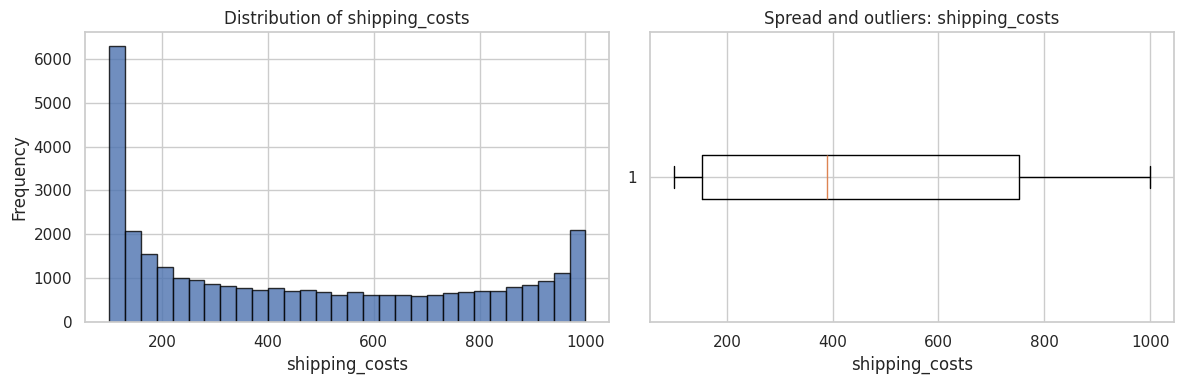

           value
count 32,065.000
mean     459.374
std      312.183
min      100.000
25%      154.017
50%      388.997
75%      753.007
90%      940.515
95%      980.829
max    1,000.000


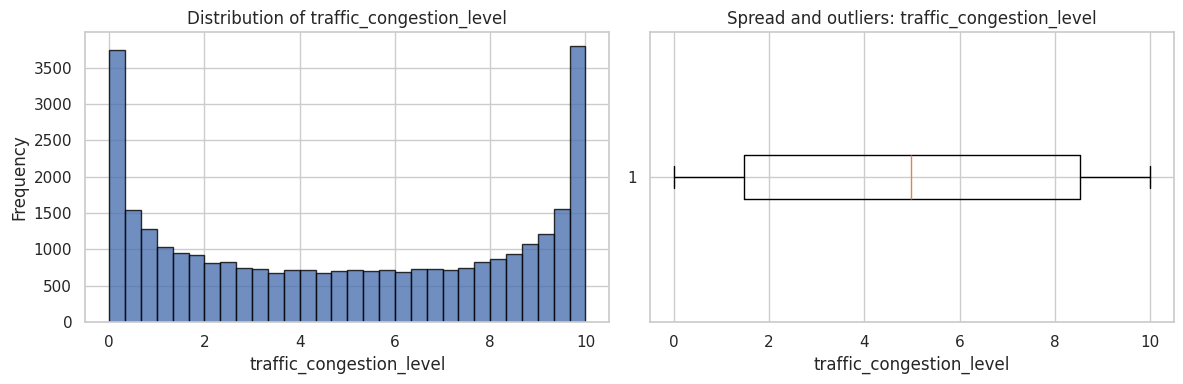

           value
count 32,065.000
mean       4.991
std        3.532
min        0.000
25%        1.475
50%        4.981
75%        8.535
90%        9.761
95%        9.939
max       10.000


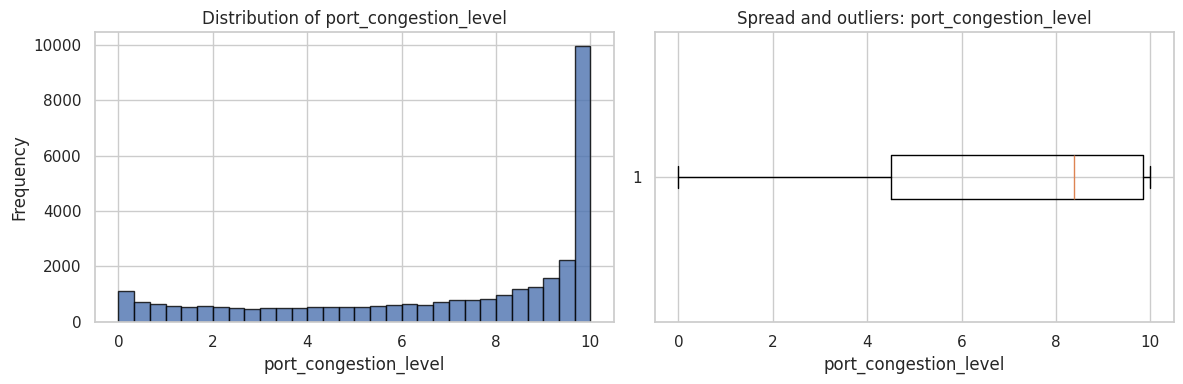

           value
count 32,065.000
mean       6.978
std        3.251
min        0.000
25%        4.514
50%        8.383
75%        9.838
90%        9.993
95%        9.999
max       10.000


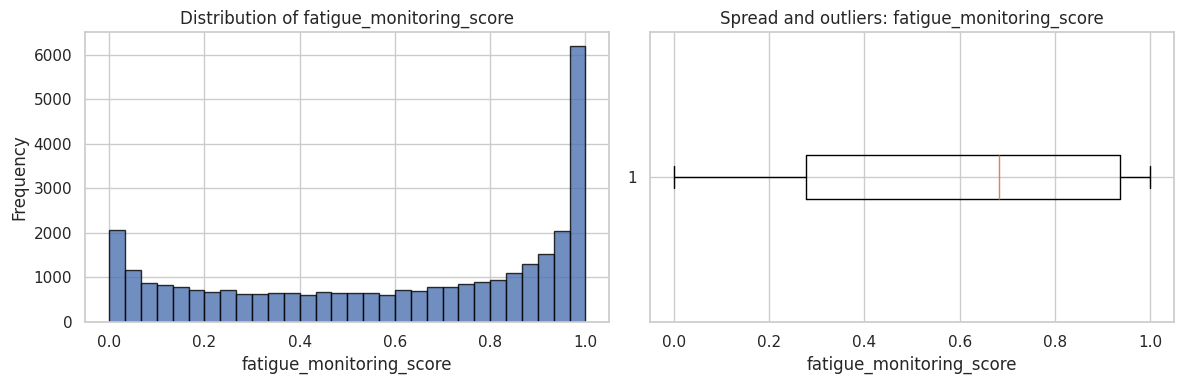

           value
count 32,065.000
mean       0.601
std        0.346
min        0.000
25%        0.278
50%        0.683
75%        0.937
90%        0.993
95%        0.999
max        1.000


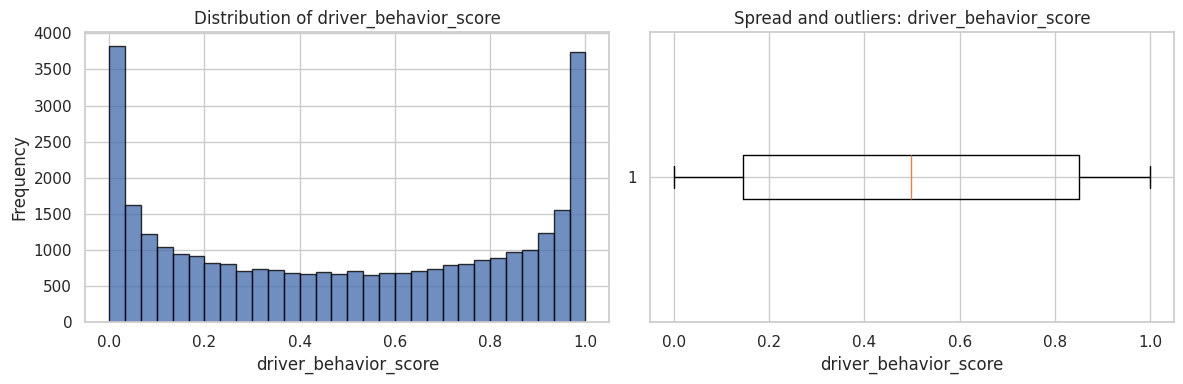

           value
count 32,065.000
mean       0.498
std        0.354
min        0.000
25%        0.144
50%        0.499
75%        0.851
90%        0.976
95%        0.994
max        1.000


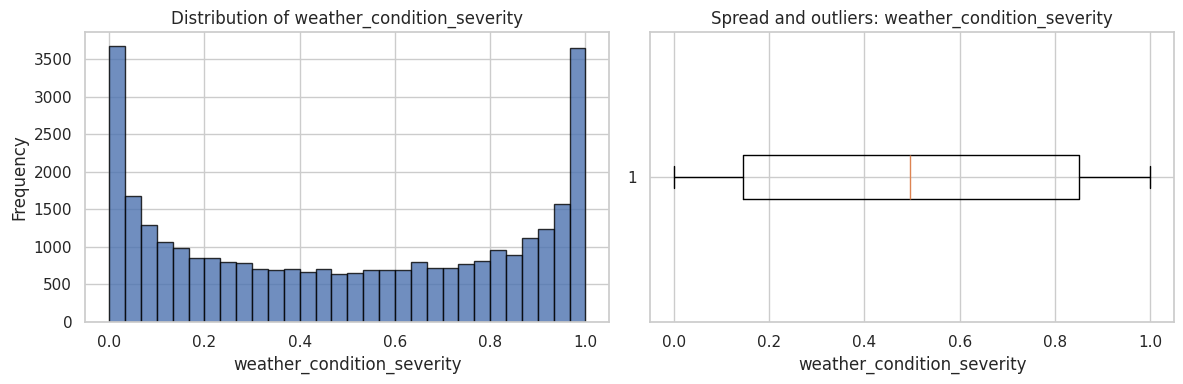

           value
count 32,065.000
mean       0.498
std        0.353
min        0.000
25%        0.144
50%        0.496
75%        0.850
90%        0.974
95%        0.994
max        1.000


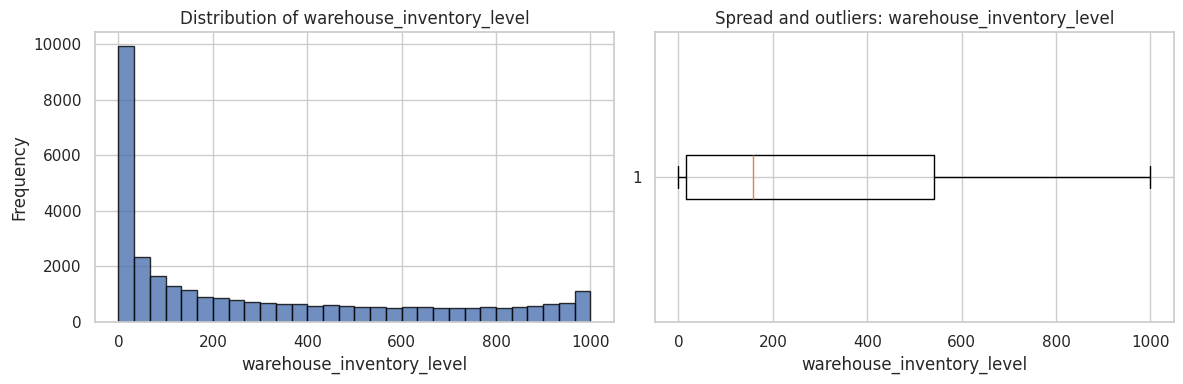

           value
count 32,065.000
mean     299.255
std      323.444
min        0.000
25%       16.052
50%      157.288
75%      540.598
90%      852.679
95%      944.700
max      999.999


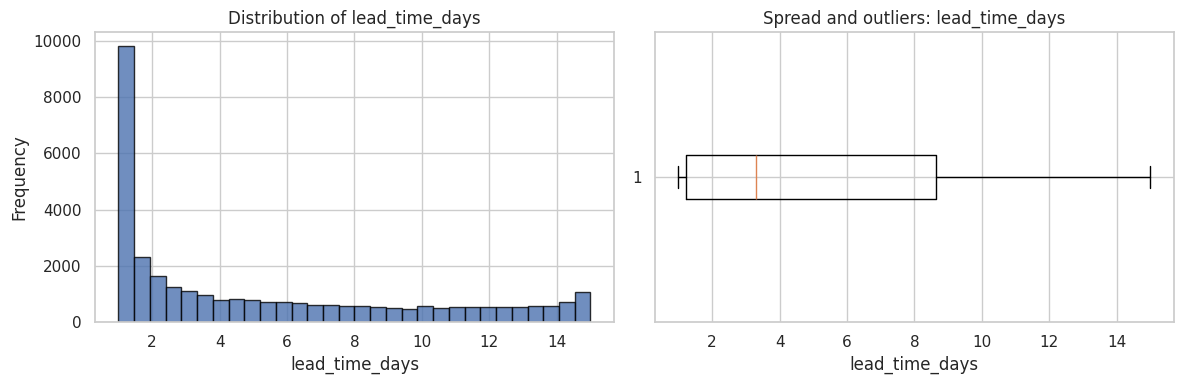

           value
count 32,065.000
mean       5.228
std        4.523
min        1.000
25%        1.237
50%        3.298
75%        8.626
90%       12.898
95%       14.192
max       15.000


In [6]:
def plot_hist_box(column, bins=30):
    values = data[column].dropna()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(values, bins=bins, edgecolor="black", alpha=0.8)
    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column); axes[0].set_ylabel("Frequency")
    axes[1].boxplot(values, vert=False)
    axes[1].set_title(f"Spread and outliers: {column}")
    axes[1].set_xlabel(column)
    plt.tight_layout(); plt.show()
    print(values.describe(percentiles=[.25, .5, .75, .9, .95]).to_frame("value"))

for col in ["shipping_costs", "traffic_congestion_level", "port_congestion_level",
            "fatigue_monitoring_score", "driver_behavior_score", "weather_condition_severity",
            "warehouse_inventory_level", "lead_time_days"]:
    plot_hist_box(col)

### 5.1 Shipping cost distribution

Mean shipping cost: $459.37
Median shipping cost: $389.00
Standard deviation: $312.18
Skewness: 0.387
Interpretation: Not strongly right-skewed based on the conventional 0.5 heuristic.


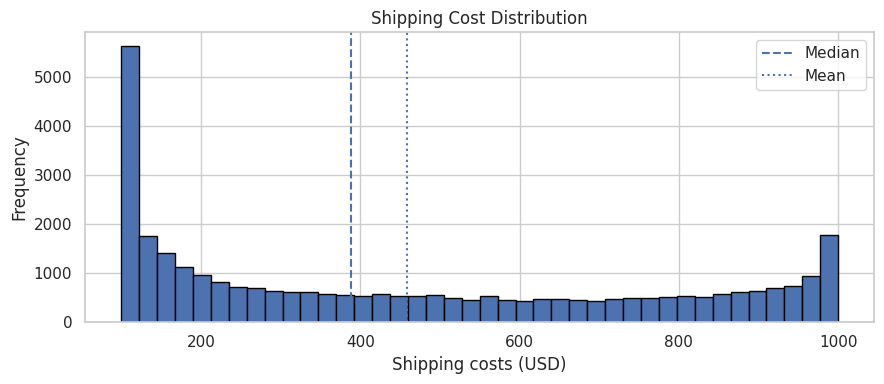

In [7]:
cost = data["shipping_costs"].dropna()
print(f"Mean shipping cost: ${cost.mean():,.2f}")
print(f"Median shipping cost: ${cost.median():,.2f}")
print(f"Standard deviation: ${cost.std():,.2f}")
print(f"Skewness: {cost.skew():.3f}")
print("Interpretation:", "Right-skewed: a smaller number of high-cost observations pull the mean upward." if cost.skew() > 0.5 else "Not strongly right-skewed based on the conventional 0.5 heuristic.")
plt.figure(figsize=(9, 4)); plt.hist(cost, bins=40, edgecolor="black"); plt.axvline(cost.median(), linestyle="--", label="Median"); plt.axvline(cost.mean(), linestyle=":", label="Mean")
plt.title("Shipping Cost Distribution"); plt.xlabel("Shipping costs (USD)"); plt.ylabel("Frequency"); plt.legend(); plt.tight_layout(); plt.show()

### 5.2 Congestion severity and bottleneck hours

traffic_congestion_level: mean=4.99, median=4.98, hours >= 7: 36.54%
port_congestion_level: mean=6.98, median=8.38, hours >= 7: 61.02%


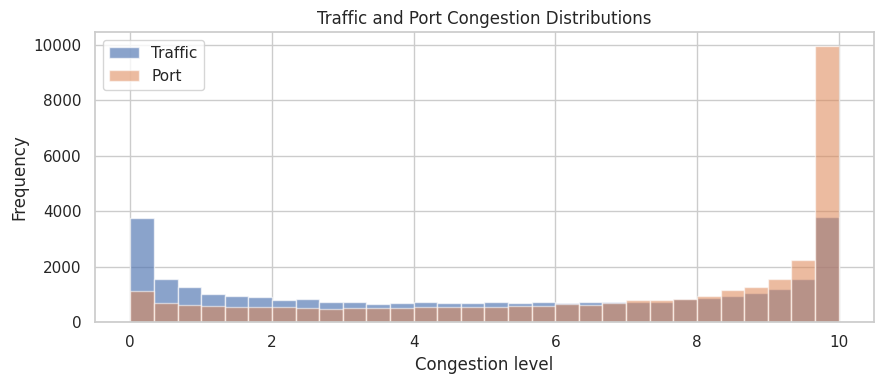

In [8]:
# Severe congestion is operationally defined here as a level >= 7 on the described 0–10 scale.
for col in ["traffic_congestion_level", "port_congestion_level"]:
    severe_pct = (data[col] >= 7).mean() * 100
    print(f"{col}: mean={data[col].mean():.2f}, median={data[col].median():.2f}, hours >= 7: {severe_pct:.2f}%")
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(data["traffic_congestion_level"], bins=30, alpha=.65, label="Traffic")
ax.hist(data["port_congestion_level"], bins=30, alpha=.55, label="Port")
ax.set(title="Traffic and Port Congestion Distributions", xlabel="Congestion level", ylabel="Frequency"); ax.legend(); plt.tight_layout(); plt.show()

### 5.3 Fulfillment and cargo condition


order_fulfillment_status: unique values (first 12) = [np.float64(1.3177636062343215e-06), np.float64(1.7096160979708443e-06), np.float64(2.5991805687891173e-06), np.float64(2.6210420763071847e-06), np.float64(2.6667764983600323e-06), np.float64(4.346301291738074e-06), np.float64(6.086780848049429e-06), np.float64(6.324432397168434e-06), np.float64(6.703619392339971e-06), np.float64(6.792626763783513e-06), np.float64(6.87032042364791e-06), np.float64(8.440670404360214e-06)]
Descriptive mean (not a verified success rate): 0.601
A >= 0.5 proxy proportion is shown only for exploratory reference: 61.71%


,value
count,"32,065.000"
mean,0.601
std,0.346
min,0.000
25%,0.277
50%,0.681
75%,0.938
max,1.000



cargo_condition_status: unique values (first 12) = [np.float64(7.255414878683799e-19), np.float64(2.57494828341729e-17), np.float64(5.2008730261712856e-15), np.float64(6.429336681865036e-14), np.float64(7.76461641888047e-14), np.float64(3.299320001793836e-13), np.float64(6.682137994058832e-13), np.float64(9.3740475059091e-13), np.float64(1.0041554858405473e-12), np.float64(1.2324233534268405e-12), np.float64(1.251221090092966e-12), np.float64(1.6159767705954845e-12)]


Descriptive mean (not a verified success rate): 0.297
A >= 0.5 proxy proportion is shown only for exploratory reference: 27.00%


,value
count,"32,065.000"
mean,0.297
std,0.322
min,0.000
25%,0.017
50%,0.155
75%,0.541
max,1.000


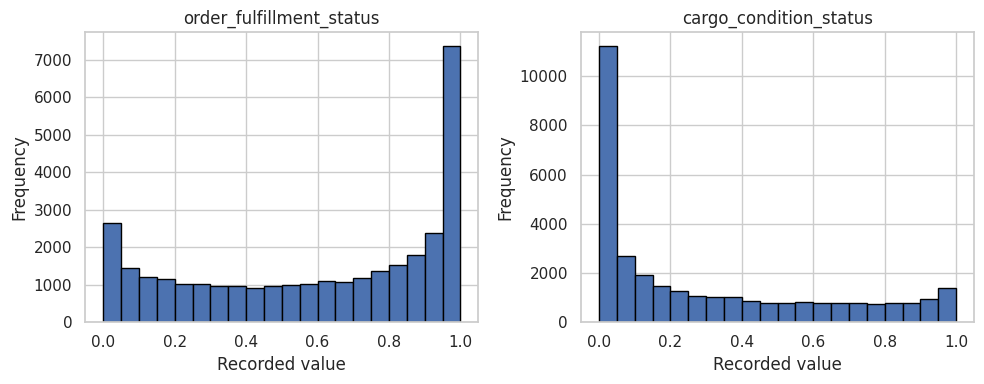

In [9]:
def binary_or_proxy_summary(series, label):
    vals = set(series.dropna().unique())
    print(f"\n{label}: unique values (first 12) = {sorted(vals)[:12]}")
    if vals.issubset({0, 1}):
        print(f"Verified binary 1 proportion: {(series == 1).mean()*100:.2f}%")
        display(series.value_counts(dropna=False).rename_axis(label).to_frame("count"))
    else:
        print("WARNING: values are not strictly binary; a binary success rate cannot be verified from this field.")
        print(f"Descriptive mean (not a verified success rate): {series.mean():.3f}")
        print("A >= 0.5 proxy proportion is shown only for exploratory reference:", f"{(series >= 0.5).mean()*100:.2f}%")
        display(series.describe().to_frame("value"))

binary_or_proxy_summary(data["order_fulfillment_status"], "order_fulfillment_status")
binary_or_proxy_summary(data["cargo_condition_status"], "cargo_condition_status")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["order_fulfillment_status", "cargo_condition_status"]):
    ax.hist(data[col].dropna(), bins=20, edgecolor="black")
    ax.set_title(col); ax.set_xlabel("Recorded value"); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()

## 6. Bivariate analysis
Pairwise relationships are explored using scatterplots and Pearson/Spearman correlations. Pearson measures linear association; Spearman measures monotonic association and is less sensitive to non-normal distributions.

traffic_congestion_level vs eta_variation_hours | n=32,065
Pearson r=-0.005, p=0.379; Spearman rho=-0.004, p=0.501


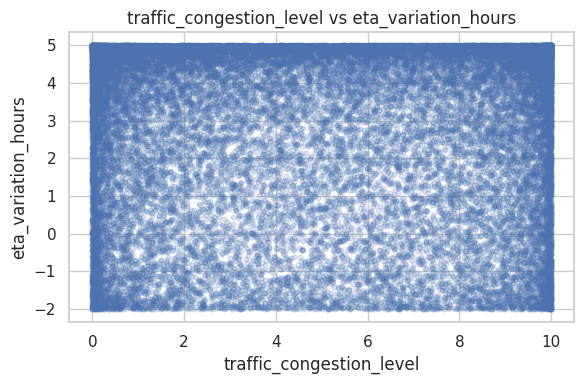

traffic_congestion_level vs delivery_time_deviation | n=32,065
Pearson r=0.001, p=0.927; Spearman rho=-0.003, p=0.566


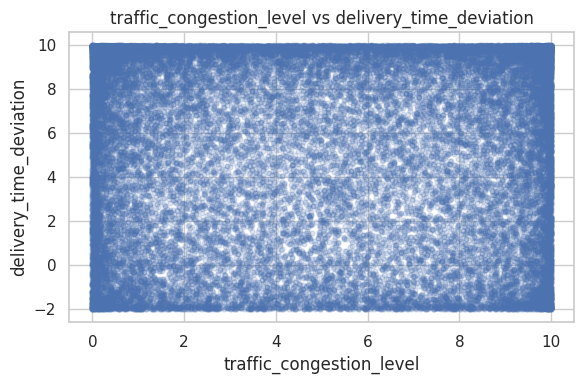

supplier_reliability_score vs lead_time_days | n=32,065
Pearson r=-0.013, p=0.0195; Spearman rho=-0.012, p=0.0313


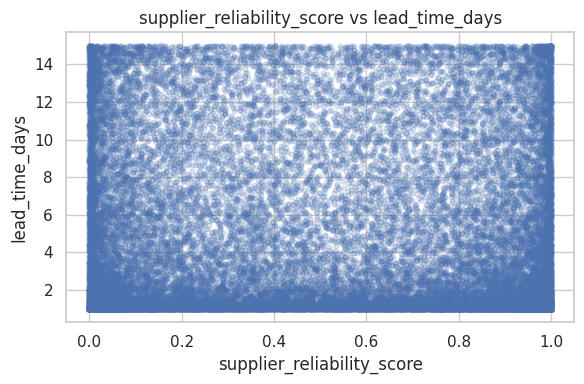

supplier_reliability_score vs warehouse_inventory_level | n=32,065
Pearson r=-0.005, p=0.371; Spearman rho=-0.006, p=0.276


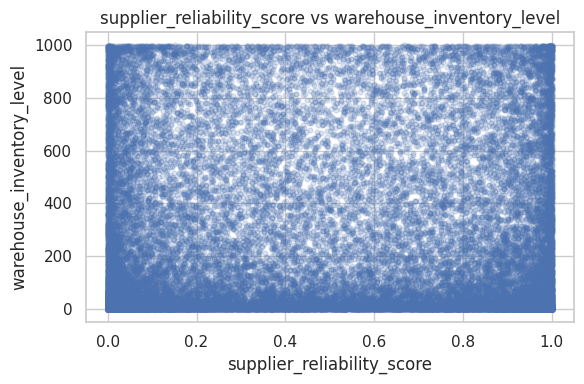

fatigue_monitoring_score vs driver_behavior_score | n=32,065
Pearson r=0.007, p=0.215; Spearman rho=0.006, p=0.272


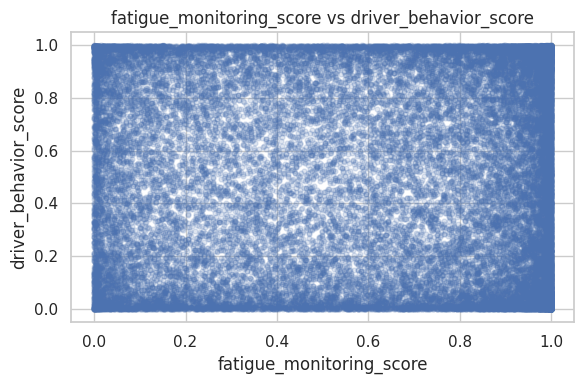

port_congestion_level vs customs_clearance_time | n=32,065
Pearson r=0.005, p=0.362; Spearman rho=0.005, p=0.387


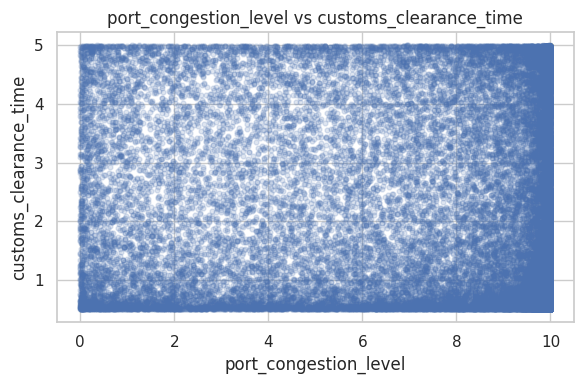

weather_condition_severity vs fuel_consumption_rate | n=32,065
Pearson r=-0.008, p=0.132; Spearman rho=-0.009, p=0.11


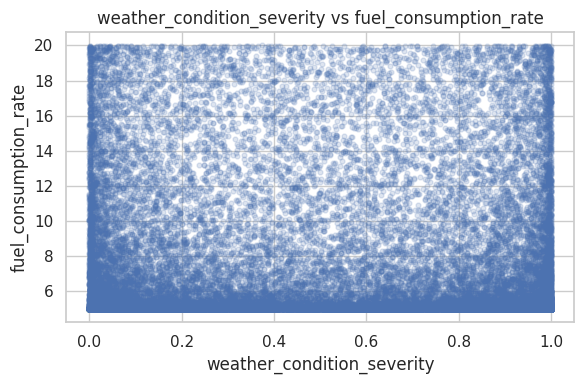

weather_condition_severity vs shipping_costs | n=32,065
Pearson r=-0.007, p=0.234; Spearman rho=-0.008, p=0.139


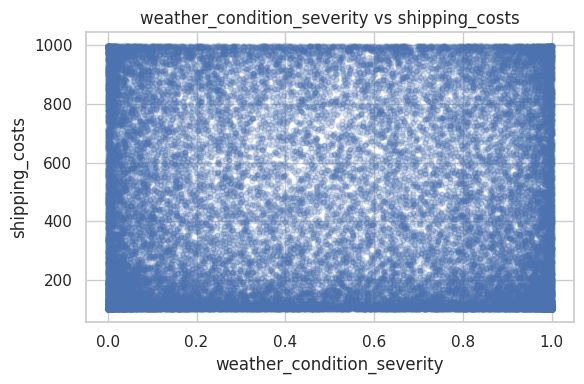

,x,y,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,traffic_congestion_level,eta_variation_hours,32065,-0.005,0.379,-0.004,0.501
1,traffic_congestion_level,delivery_time_deviation,32065,0.001,0.927,-0.003,0.566
2,supplier_reliability_score,lead_time_days,32065,-0.013,0.019,-0.012,0.031
3,supplier_reliability_score,warehouse_inventory_level,32065,-0.005,0.371,-0.006,0.276
4,fatigue_monitoring_score,driver_behavior_score,32065,0.007,0.215,0.006,0.272
5,port_congestion_level,customs_clearance_time,32065,0.005,0.362,0.005,0.387
6,weather_condition_severity,fuel_consumption_rate,32065,-0.008,0.132,-0.009,0.110
7,weather_condition_severity,shipping_costs,32065,-0.007,0.234,-0.008,0.139


In [10]:
def correlation_report(x, y, label=None, make_plot=True):
    pair = data[[x, y]].dropna()
    if len(pair) < 3 or pair[x].nunique() < 2 or pair[y].nunique() < 2:
        print(f"Insufficient variation/data for {x} vs {y}"); return
    pearson_r, pearson_p = stats.pearsonr(pair[x], pair[y])
    spearman_r, spearman_p = stats.spearmanr(pair[x], pair[y])
    print(f"{label or (x+' vs '+y)} | n={len(pair):,}")
    print(f"Pearson r={pearson_r:.3f}, p={pearson_p:.3g}; Spearman rho={spearman_r:.3f}, p={spearman_p:.3g}")
    if make_plot:
        plt.figure(figsize=(6, 4)); plt.scatter(pair[x], pair[y], alpha=.18, s=12)
        plt.xlabel(x); plt.ylabel(y); plt.title(label or f"{x} vs {y}"); plt.tight_layout(); plt.show()
    return {"x": x, "y": y, "n": len(pair), "pearson_r": pearson_r, "pearson_p": pearson_p, "spearman_rho": spearman_r, "spearman_p": spearman_p}

bi_results = []
for x, y in [("traffic_congestion_level", "eta_variation_hours"),
             ("traffic_congestion_level", "delivery_time_deviation"),
             ("supplier_reliability_score", "lead_time_days"),
             ("supplier_reliability_score", "warehouse_inventory_level"),
             ("fatigue_monitoring_score", "driver_behavior_score"),
             ("port_congestion_level", "customs_clearance_time"),
             ("weather_condition_severity", "fuel_consumption_rate"),
             ("weather_condition_severity", "shipping_costs")]:
    result = correlation_report(x, y)
    if result: bi_results.append(result)
display(pd.DataFrame(bi_results))

### 6.1 Congestion vs. delay: check for non-linearity

,congestion_decile,mean,median,count
0,"(-0.00099999891, 0.249]",2.899,3.872,3207
1,"(0.249, 0.955]",2.982,4.051,3206
2,"(0.955, 2.061]",2.865,3.842,3207
3,"(2.061, 3.441]",2.908,3.850,3206
4,"(3.441, 4.981]",2.879,3.880,3207
5,"(4.981, 6.491]",2.863,3.825,3206
6,"(6.491, 7.922]",2.863,3.858,3206
7,"(7.922, 9.044]",2.831,3.794,3207
8,"(9.044, 9.761]",2.887,3.842,3206
9,"(9.761, 10.0]",2.953,4.020,3207


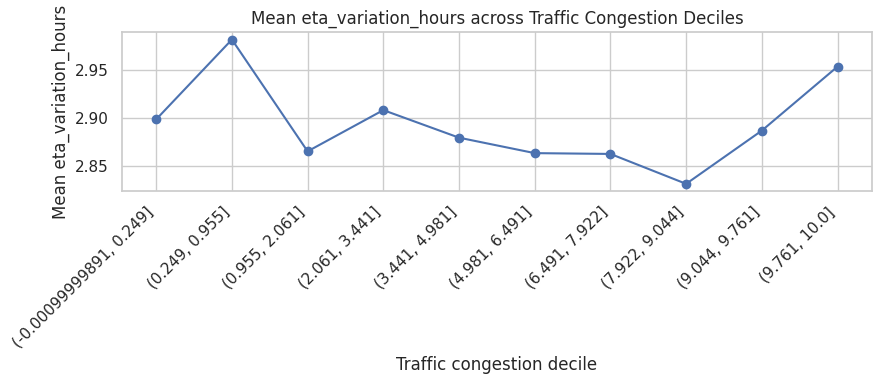

,congestion_decile,mean,median,count
0,"(-0.00099999891, 0.249]",5.297,6.360,3207
1,"(0.249, 0.955]",5.128,6.064,3206
2,"(0.955, 2.061]",5.178,6.150,3207
3,"(2.061, 3.441]",5.129,6.081,3206
4,"(3.441, 4.981]",5.190,6.172,3207
5,"(4.981, 6.491]",5.109,5.896,3206
6,"(6.491, 7.922]",5.088,5.938,3206
7,"(7.922, 9.044]",5.217,6.241,3207
8,"(9.044, 9.761]",5.308,6.201,3206
9,"(9.761, 10.0]",5.131,6.033,3207


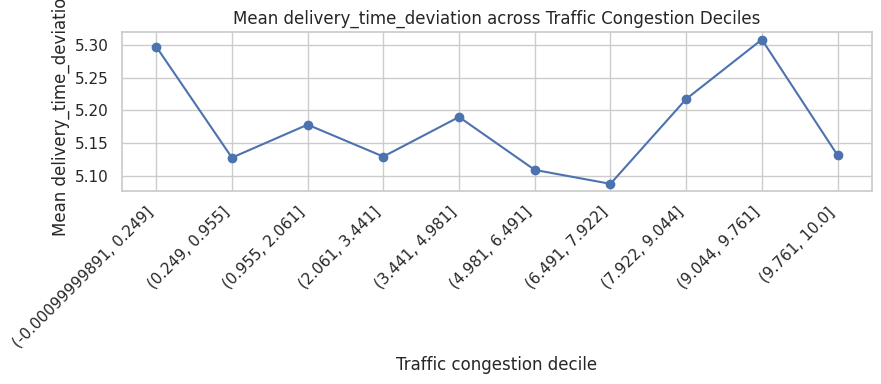

In [11]:
# Compare average delay by congestion decile; this can reveal non-linear patterns.
for target in ["eta_variation_hours", "delivery_time_deviation"]:
    temp = data[["traffic_congestion_level", target]].dropna().copy()
    temp["congestion_decile"] = pd.qcut(temp["traffic_congestion_level"], q=10, duplicates="drop")
    grouped = temp.groupby("congestion_decile", observed=True)[target].agg(["mean", "median", "count"]).reset_index()
    display(grouped)
    plt.figure(figsize=(9, 4)); plt.plot(range(len(grouped)), grouped["mean"], marker="o")
    plt.xticks(range(len(grouped)), [str(x) for x in grouped["congestion_decile"]], rotation=45, ha="right")
    plt.title(f"Mean {target} across Traffic Congestion Deciles"); plt.xlabel("Traffic congestion decile"); plt.ylabel(f"Mean {target}"); plt.tight_layout(); plt.show()

## 7. Multivariate analysis
These views examine combined operational factors. The target columns are analyzed as recorded; no predictive model is claimed in this descriptive EDA.

### 7.1 Correlation matrix of key logistics variables

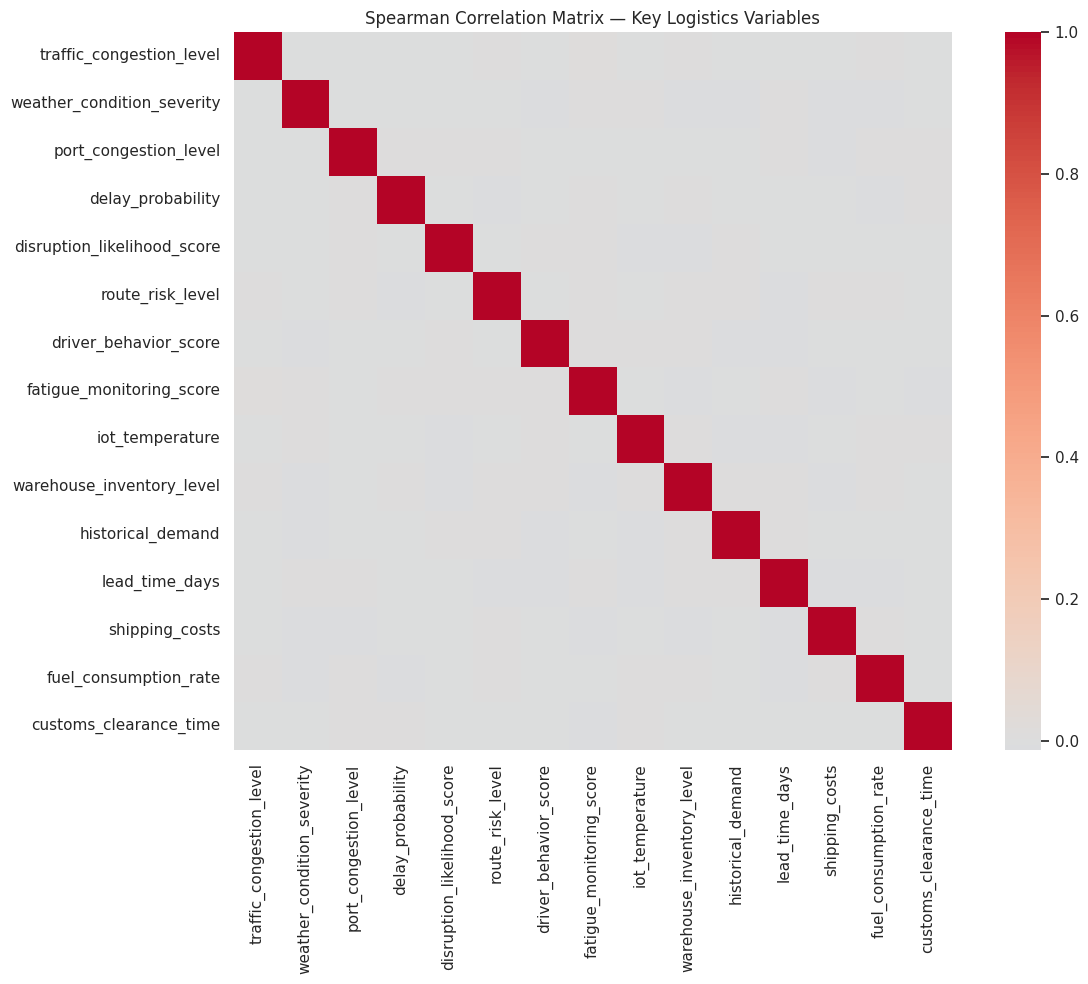

Top absolute Spearman associations with delay_probability:


,absolute_spearman_rho,signed_spearman_rho
fuel_consumption_rate,0.014,-0.014
route_risk_level,0.007,-0.007
port_congestion_level,0.007,0.007
warehouse_inventory_level,0.006,0.006
disruption_likelihood_score,0.006,-0.006
historical_demand,0.006,-0.006
fatigue_monitoring_score,0.005,0.005
driver_behavior_score,0.004,-0.004


Top absolute Spearman associations with disruption_likelihood_score:


,absolute_spearman_rho,signed_spearman_rho
warehouse_inventory_level,0.011,-0.011
iot_temperature,0.007,-0.007
port_congestion_level,0.007,0.007
delay_probability,0.006,-0.006
weather_condition_severity,0.005,-0.005
driver_behavior_score,0.004,0.004
historical_demand,0.003,0.003
fatigue_monitoring_score,0.003,0.003


In [12]:
multi_cols = ["traffic_congestion_level", "weather_condition_severity", "port_congestion_level",
              "delay_probability", "disruption_likelihood_score", "route_risk_level",
              "driver_behavior_score", "fatigue_monitoring_score", "iot_temperature",
              "warehouse_inventory_level", "historical_demand", "lead_time_days",
              "shipping_costs", "fuel_consumption_rate", "customs_clearance_time"]
corr = data[multi_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 10))
if sns is not None:
    sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True, ax=ax)
else:
    im=ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); fig.colorbar(im, ax=ax)
    ax.set_xticks(range(len(multi_cols))); ax.set_xticklabels(multi_cols, rotation=90)
    ax.set_yticks(range(len(multi_cols))); ax.set_yticklabels(multi_cols)
ax.set_title("Spearman Correlation Matrix — Key Logistics Variables"); plt.tight_layout(); plt.show()

# Strongest absolute associations with delay and disruption scores, excluding self-correlation.
for target in ["delay_probability", "disruption_likelihood_score"]:
    ranked = corr[target].drop(target).abs().sort_values(ascending=False)
    print(f"Top absolute Spearman associations with {target}:")
    display(pd.DataFrame({"absolute_spearman_rho": ranked, "signed_spearman_rho": corr[target].loc[ranked.index]}).head(8))

### 7.2 Delay and disruption across congestion/weather combinations

Mean delay_probability by traffic and weather bands:


weather_condition_severity_band,Low,Medium,High
traffic_congestion_level_band,,,
Low,0.702,0.701,0.693
Medium,0.695,0.701,0.713
High,0.694,0.698,0.695


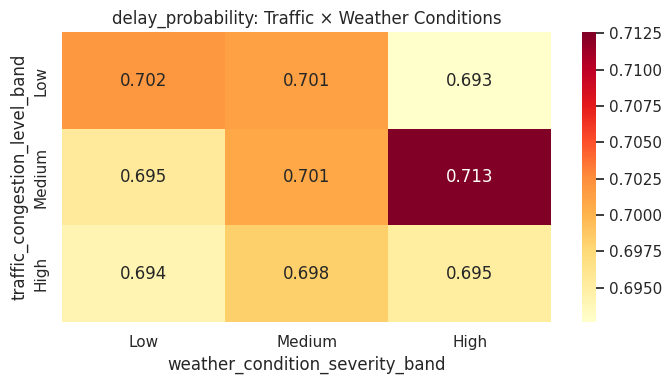

Mean disruption_likelihood_score by traffic and weather bands:


weather_condition_severity_band,Low,Medium,High
traffic_congestion_level_band,,,
Low,0.807,0.811,0.796
Medium,0.798,0.808,0.800
High,0.806,0.801,0.805


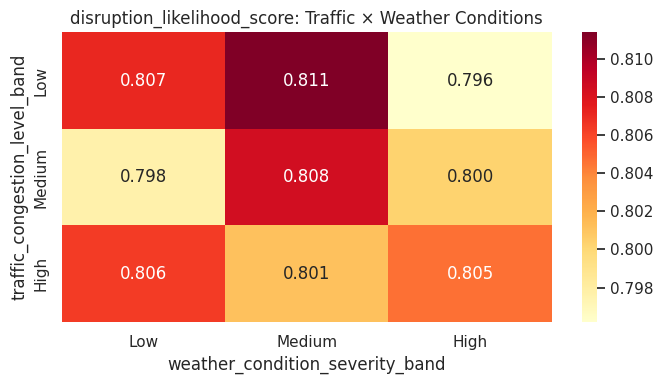

Mean delay probability by port congestion band:


,mean,median,count
port_congestion_level_band,,,
Low,0.696,0.837,10688
Medium,0.701,0.842,10689
High,0.700,0.840,10688


In [13]:
# Categorize factors into tertiles to compare joint conditions.
for col in ["traffic_congestion_level", "weather_condition_severity", "port_congestion_level"]:
    data[col + "_band"] = pd.qcut(data[col], q=3, labels=["Low", "Medium", "High"], duplicates="drop")

for target in ["delay_probability", "disruption_likelihood_score"]:
    pivot = data.pivot_table(index="traffic_congestion_level_band", columns="weather_condition_severity_band", values=target, aggfunc="mean", observed=True)
    print(f"Mean {target} by traffic and weather bands:"); display(pivot)
    plt.figure(figsize=(7, 4))
    if sns is not None: sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlOrRd")
    else: plt.imshow(pivot, aspect="auto", cmap="YlOrRd"); plt.colorbar()
    plt.title(f"{target}: Traffic × Weather Conditions"); plt.tight_layout(); plt.show()

print("Mean delay probability by port congestion band:")
display(data.groupby("port_congestion_level_band", observed=True)["delay_probability"].agg(["mean", "median", "count"]))

### 7.3 Risk classification and human / cargo factors

,records,mean_route_risk,mean_driver_behavior,mean_fatigue,mean_iot_temperature,mean_disruption_score,mean_delay_probability
risk_classification,,,,,,,
High Risk,23944,7.009,0.499,0.601,-0.007,0.949,0.699
Moderate Risk,5011,7.005,0.501,0.601,0.242,0.519,0.696
Low Risk,3110,6.934,0.490,0.598,0.124,0.143,0.707


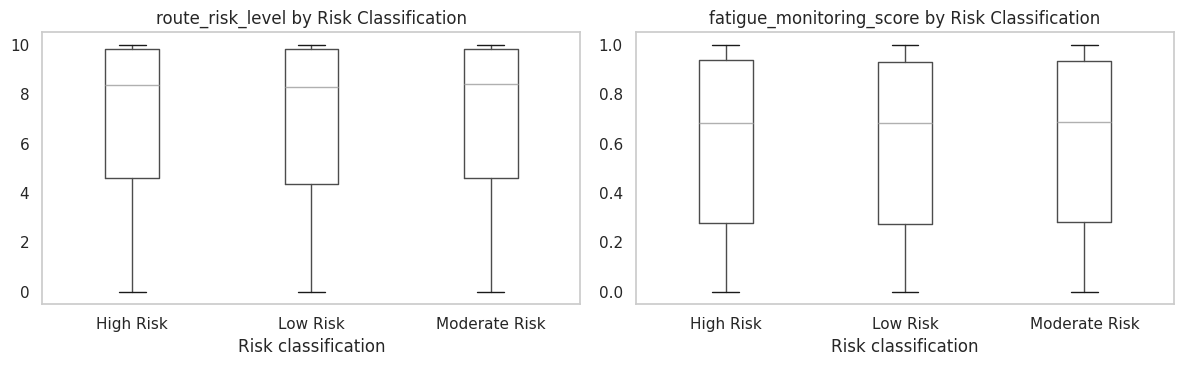

In [14]:
risk_summary = data.groupby("risk_classification", dropna=False).agg(
    records=("risk_classification", "size"),
    mean_route_risk=("route_risk_level", "mean"),
    mean_driver_behavior=("driver_behavior_score", "mean"),
    mean_fatigue=("fatigue_monitoring_score", "mean"),
    mean_iot_temperature=("iot_temperature", "mean"),
    mean_disruption_score=("disruption_likelihood_score", "mean"),
    mean_delay_probability=("delay_probability", "mean")
).sort_values("records", ascending=False)
display(risk_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["route_risk_level", "fatigue_monitoring_score"]):
    data.boxplot(column=col, by="risk_classification", ax=ax, grid=False)
    ax.set_title(f"{col} by Risk Classification"); ax.set_xlabel("Risk classification")
plt.suptitle(""); plt.tight_layout(); plt.show()

### 7.4 Warehouse inventory, demand, lead time and fulfillment

Inventory/demand ratio summary:


,value
count,"32,065.000"
mean,0.189
std,0.675
min,0.000
25%,0.003
50%,0.032
75%,0.100
max,9.889


warehouse_inventory_level vs recorded fulfillment field | n=32,065
Pearson r=-0.005, p=0.37; Spearman rho=-0.006, p=0.303


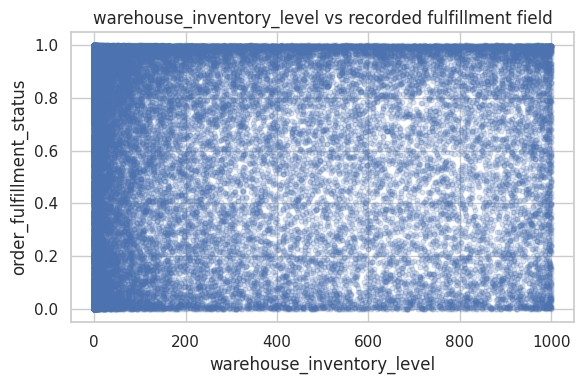

historical_demand vs recorded fulfillment field | n=32,065
Pearson r=0.004, p=0.507; Spearman rho=0.004, p=0.44


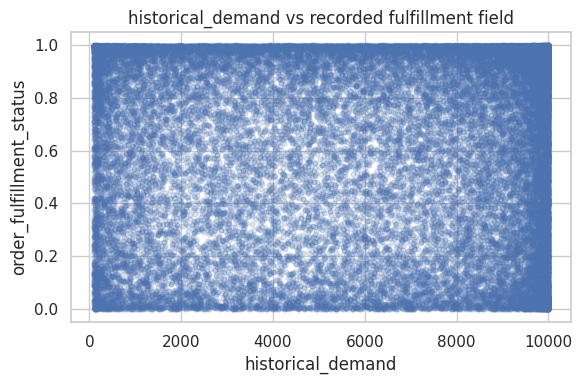

lead_time_days vs recorded fulfillment field | n=32,065
Pearson r=0.009, p=0.125; Spearman rho=0.007, p=0.214


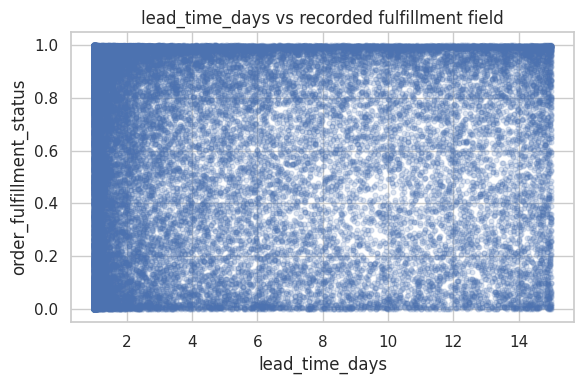

inventory_demand_ratio vs recorded fulfillment field | n=32,065
Pearson r=0.009, p=0.121; Spearman rho=-0.005, p=0.329


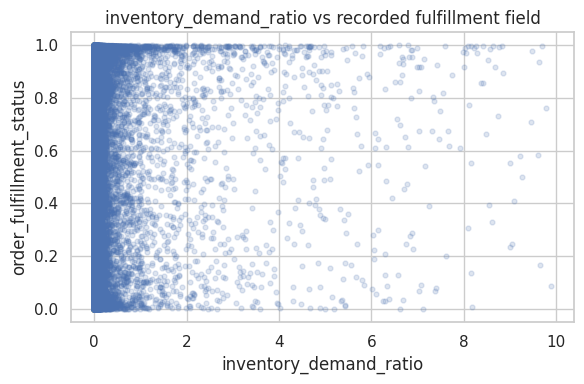

lead_time_days_band,Low,Medium,High
historical_demand_band,,,
Low,0.597,0.598,0.599
Medium,0.601,0.598,0.604
High,0.601,0.594,0.614


In [15]:
# Inventory-to-demand ratio is a descriptive buffer proxy; zero demand is handled safely.
data["inventory_demand_ratio"] = data["warehouse_inventory_level"] / data["historical_demand"].replace(0, np.nan)
print("Inventory/demand ratio summary:"); display(data["inventory_demand_ratio"].describe().to_frame("value"))

for col in ["warehouse_inventory_level", "historical_demand", "lead_time_days", "inventory_demand_ratio"]:
    correlation_report(col, "order_fulfillment_status", label=f"{col} vs recorded fulfillment field", make_plot=True)

# Group by demand and lead-time terciles, compare inventory and recorded fulfillment field.
for col in ["historical_demand", "lead_time_days"]:
    data[col + "_band"] = pd.qcut(data[col], q=3, labels=["Low", "Medium", "High"], duplicates="drop")
fulfillment_pivot = data.pivot_table(index="historical_demand_band", columns="lead_time_days_band", values="order_fulfillment_status", aggfunc="mean", observed=True)
display(fulfillment_pivot)

### 7.5 Cost escalation across fuel, customs and route risk

,mean_shipping_cost,median_shipping_cost,mean_factor,records
route_risk_band,,,,
Low,456.441,382.151,7.966,10688
Medium,460.204,389.686,8.022,10689
High,461.478,395.007,8.047,10688


<Figure size 700x400 with 0 Axes>

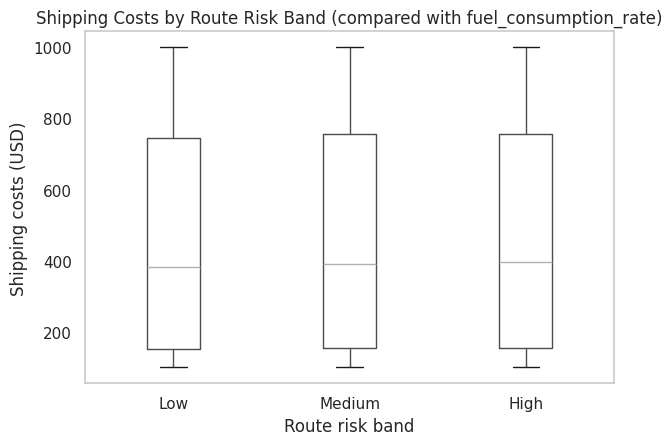

,mean_shipping_cost,median_shipping_cost,mean_factor,records
route_risk_band,,,,
Low,456.441,382.151,2.307,10688
Medium,460.204,389.686,2.289,10689
High,461.478,395.007,2.293,10688


<Figure size 700x400 with 0 Axes>

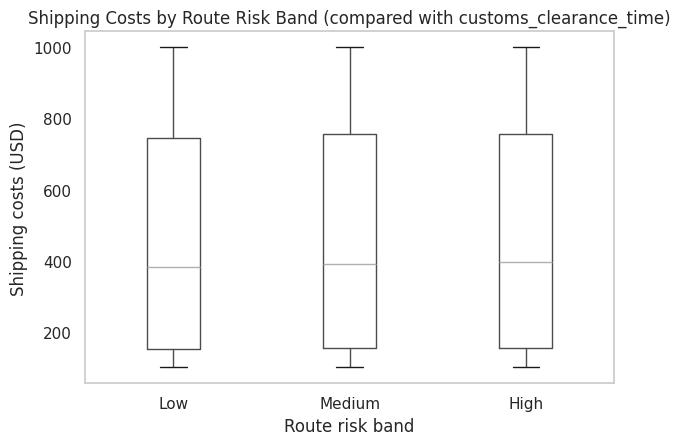

fuel_consumption_rate vs shipping_costs | n=32,065
Pearson r=0.005, p=0.367; Spearman rho=0.008, p=0.161


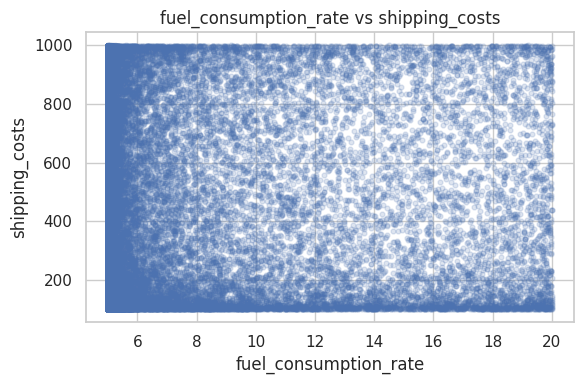

customs_clearance_time vs shipping_costs | n=32,065
Pearson r=-0.001, p=0.88; Spearman rho=0.001, p=0.89


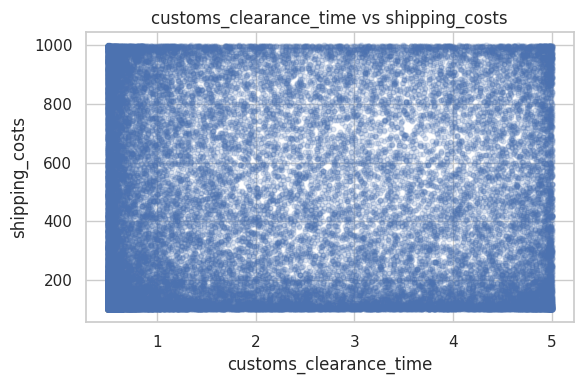

{'x': 'customs_clearance_time',
 'y': 'shipping_costs',
 'n': 32065,
 'pearson_r': np.float64(-0.0008410956005752215),
 'pearson_p': np.float64(0.880286020497527),
 'spearman_rho': np.float64(0.0007756614391906202),
 'spearman_p': np.float64(0.8895370781813688)}

In [16]:
data["route_risk_band"] = pd.qcut(data["route_risk_level"], q=3, labels=["Low", "Medium", "High"], duplicates="drop")
for col in ["fuel_consumption_rate", "customs_clearance_time"]:
    display(data.groupby("route_risk_band", observed=True).agg(
        mean_shipping_cost=("shipping_costs", "mean"), median_shipping_cost=("shipping_costs", "median"),
        mean_factor=(col, "mean"), records=("shipping_costs", "size")
    ))
    plt.figure(figsize=(7, 4))
    data.boxplot(column="shipping_costs", by="route_risk_band", grid=False)
    plt.title(f"Shipping Costs by Route Risk Band (compared with {col})"); plt.suptitle(""); plt.xlabel("Route risk band"); plt.ylabel("Shipping costs (USD)"); plt.tight_layout(); plt.show()

correlation_report("fuel_consumption_rate", "shipping_costs")
correlation_report("customs_clearance_time", "shipping_costs")

## 8. Temporal analysis
Temporal analysis uses the parsed timestamp and extracted calendar features. The dataset is hourly in the description; the actual timestamp spacing is checked here.

In [17]:
time_diffs = data["timestamp"].sort_values().diff().dropna()
print("Most common timestamp intervals:")
display(time_diffs.value_counts().head(10).rename_axis("interval").to_frame("count"))
print("Years present:", sorted(data["year"].unique().tolist()))
print("Monthly record counts:")
display(data.groupby(data["timestamp"].dt.to_period("M")).size().describe().to_frame("monthly_record_count"))

Most common timestamp intervals:


,count
interval,
0 days 01:00:00,32064


Years present: [2021, 2022, 2023, 2024]
Monthly record counts:


,monthly_record_count
count,44.000
mean,728.750
std,21.956
min,672.000
25%,720.000
50%,744.000
75%,744.000
max,744.000


### 8.1 Hourly and daily congestion cycles

,mean_traffic_congestion,mean_fuel_consumption,records
hour_of_day,,,
0,5.155,7.947,1337
1,5.046,8.079,1336
2,5.088,7.827,1336
3,5.005,7.984,1336
4,4.921,8.088,1336
5,5.009,7.955,1336
6,5.075,8.031,1336
7,5.068,8.069,1336
8,5.164,7.908,1336


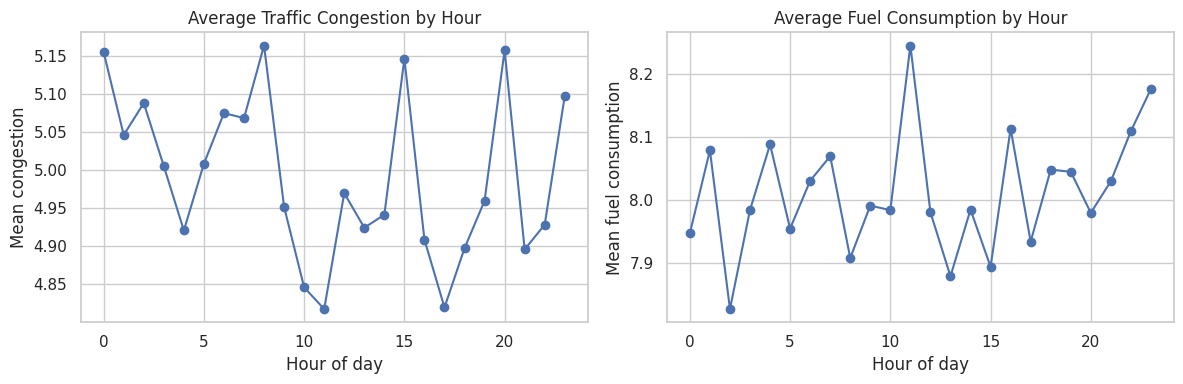

,mean_traffic,mean_fuel
day_of_week,,
Monday,5.029,8.108
Tuesday,5.024,8.023
Wednesday,4.942,8.006
Thursday,4.971,8.027
Friday,4.996,7.925
Saturday,4.915,7.903
Sunday,5.062,8.091


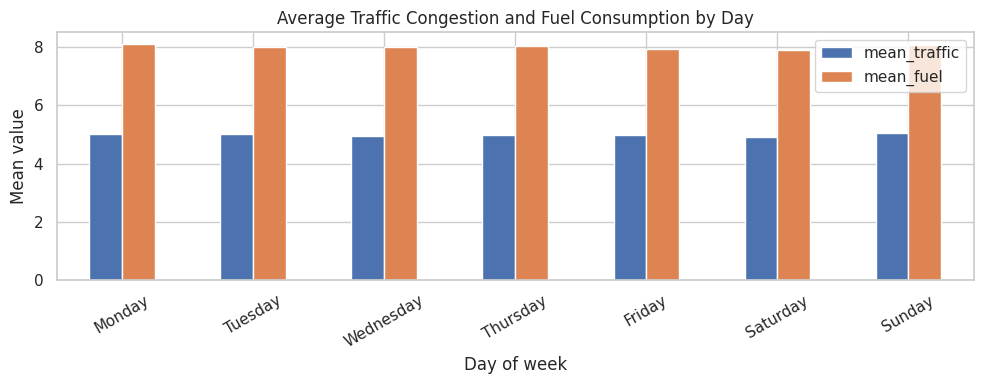

In [18]:
hourly = data.groupby("hour_of_day").agg(
    mean_traffic_congestion=("traffic_congestion_level", "mean"),
    mean_fuel_consumption=("fuel_consumption_rate", "mean"),
    records=("timestamp", "size")
)
display(hourly)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hourly["mean_traffic_congestion"].plot(marker="o", ax=axes[0]); axes[0].set(title="Average Traffic Congestion by Hour", xlabel="Hour of day", ylabel="Mean congestion")
hourly["mean_fuel_consumption"].plot(marker="o", ax=axes[1]); axes[1].set(title="Average Fuel Consumption by Hour", xlabel="Hour of day", ylabel="Mean fuel consumption")
plt.tight_layout(); plt.show()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = data.groupby("day_of_week").agg(mean_traffic=("traffic_congestion_level", "mean"), mean_fuel=("fuel_consumption_rate", "mean")).reindex(day_order)
display(daily)
daily.plot(kind="bar", figsize=(10, 4)); plt.title("Average Traffic Congestion and Fuel Consumption by Day"); plt.xlabel("Day of week"); plt.ylabel("Mean value"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

### 8.2 Year-over-year shipping costs, inventory and demand

,mean_shipping_cost,median_shipping_cost,mean_inventory,mean_historical_demand,records
year,,,,,
2021,458.555,391.031,299.022,"6,035.848",8760
2022,456.891,378.910,300.885,"6,010.893",8760
2023,459.579,390.115,297.623,"5,997.049",8760
2024,464.068,405.549,299.607,"6,055.640",5785


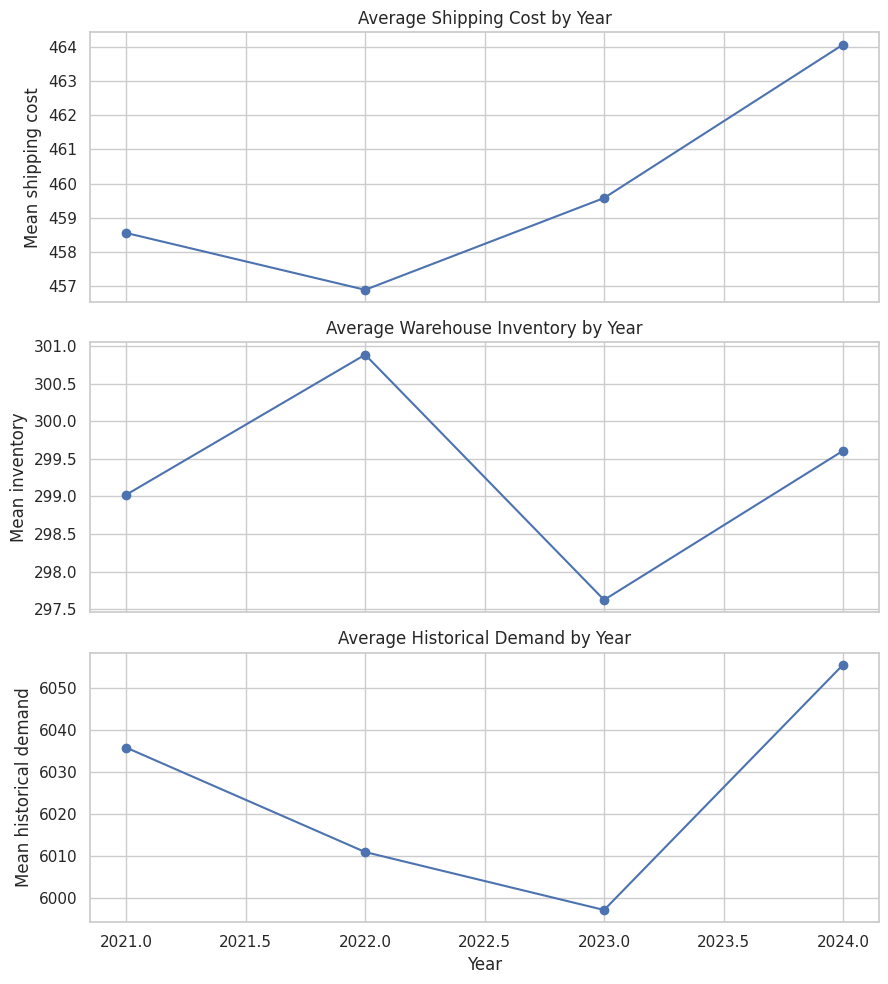

In [19]:
yearly = data.groupby("year").agg(
    mean_shipping_cost=("shipping_costs", "mean"),
    median_shipping_cost=("shipping_costs", "median"),
    mean_inventory=("warehouse_inventory_level", "mean"),
    mean_historical_demand=("historical_demand", "mean"),
    records=("timestamp", "size")
)
display(yearly)
fig, axes = plt.subplots(3, 1, figsize=(9, 10), sharex=True)
for ax, col, title in zip(axes, ["mean_shipping_cost", "mean_inventory", "mean_historical_demand"], ["Average Shipping Cost by Year", "Average Warehouse Inventory by Year", "Average Historical Demand by Year"]):
    yearly[col].plot(marker="o", ax=ax); ax.set_title(title); ax.set_ylabel(col.replace("mean_", "Mean ").replace("_", " "))
axes[-1].set_xlabel("Year"); plt.tight_layout(); plt.show()

### 8.3 Seasonal weather and disruption patterns

,mean_weather_severity,mean_disruption_score,mean_delay_probability,records
Jan,0.505,0.808,0.700,2976
Feb,0.506,0.802,0.709,2712
Mar,0.502,0.810,0.691,2976
Apr,0.495,0.809,0.703,2880
May,0.498,0.803,0.703,2976
Jun,0.509,0.800,0.706,2880
Jul,0.492,0.798,0.692,2976
Aug,0.494,0.808,0.692,2905
Sep,0.482,0.801,0.702,2160
Oct,0.494,0.793,0.700,2232


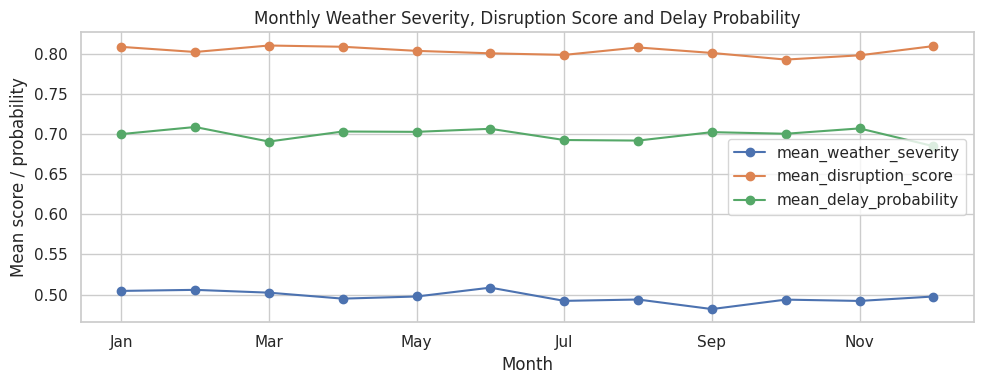

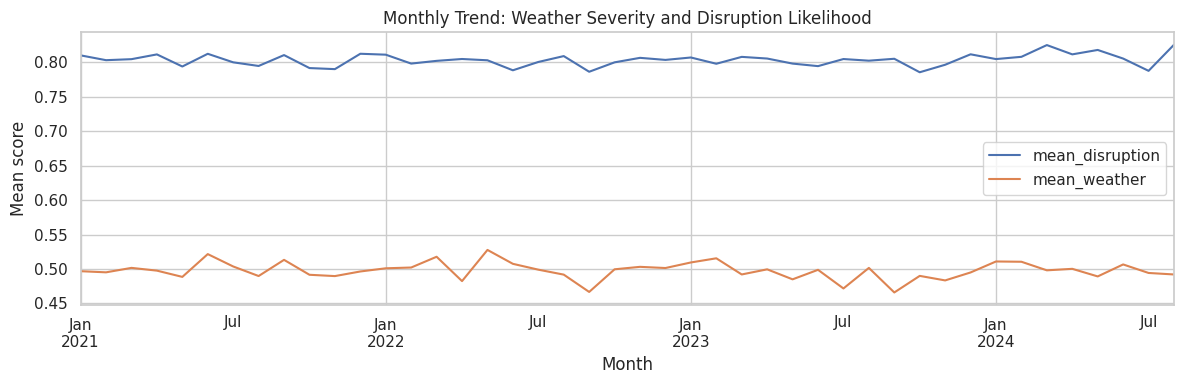

In [20]:
monthly = data.groupby("month").agg(
    mean_weather_severity=("weather_condition_severity", "mean"),
    mean_disruption_score=("disruption_likelihood_score", "mean"),
    mean_delay_probability=("delay_probability", "mean"),
    records=("timestamp", "size")
).reindex(range(1, 13))
monthly.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in monthly.index]
display(monthly)
monthly[["mean_weather_severity", "mean_disruption_score", "mean_delay_probability"]].plot(marker="o", figsize=(10, 4))
plt.title("Monthly Weather Severity, Disruption Score and Delay Probability"); plt.xlabel("Month"); plt.ylabel("Mean score / probability"); plt.tight_layout(); plt.show()

# Year-month trend to distinguish recurring seasonality from one-off yearly changes.
data["year_month"] = data["timestamp"].dt.to_period("M").dt.to_timestamp()
monthly_trend = data.groupby("year_month").agg(mean_disruption=("disruption_likelihood_score", "mean"), mean_weather=("weather_condition_severity", "mean"))
monthly_trend.plot(figsize=(12, 4)); plt.title("Monthly Trend: Weather Severity and Disruption Likelihood"); plt.xlabel("Month"); plt.ylabel("Mean score"); plt.tight_layout(); plt.show()

### 8.4 Loading/unloading and customs clearance latency over time

,mean_loading_unloading,mean_customs_clearance
year_month,,
2021-01-01,2.314,2.275
2021-02-01,2.270,2.276
2021-03-01,2.228,2.296
2021-04-01,2.230,2.411
2021-05-01,2.295,2.311


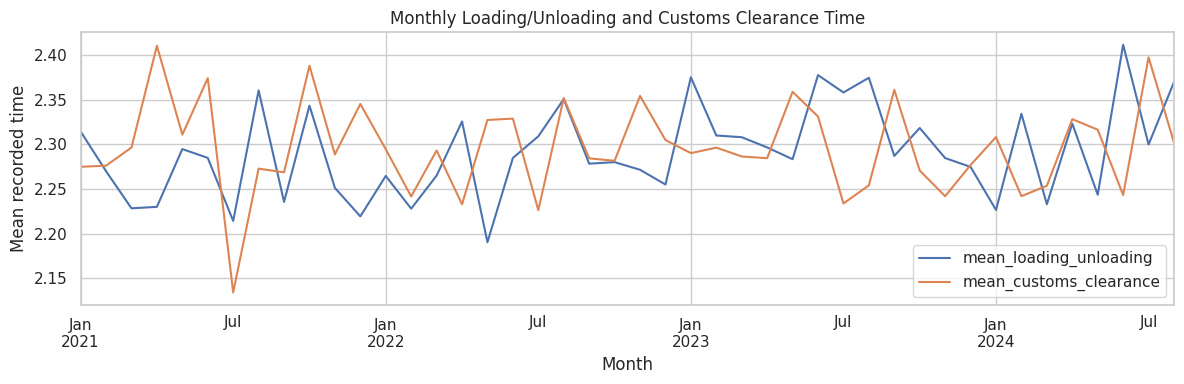

In [21]:
latency_monthly = data.groupby("year_month").agg(
    mean_loading_unloading=("loading_unloading_time", "mean"),
    mean_customs_clearance=("customs_clearance_time", "mean")
)
display(latency_monthly.head())
latency_monthly.plot(figsize=(12, 4)); plt.title("Monthly Loading/Unloading and Customs Clearance Time"); plt.xlabel("Month"); plt.ylabel("Mean recorded time"); plt.tight_layout(); plt.show()

## 9. Statistical tests and hypothesis generation
The tests below are exploratory. P-values are interpreted alongside effect sizes/correlation magnitudes; with a large dataset, very small effects can become statistically significant. Multiple comparisons are not treated as confirmatory evidence.

In [22]:
# H1: Observations in the highest traffic-congestion tertile have a different ETA variation
# from observations in the lowest tertile (two-sided Mann–Whitney U test).
traffic_groups = data[["traffic_congestion_level", "eta_variation_hours"]].dropna().copy()
traffic_groups["traffic_band"] = pd.qcut(traffic_groups["traffic_congestion_level"], q=3, labels=["Low", "Medium", "High"], duplicates="drop")
low = traffic_groups.loc[traffic_groups["traffic_band"] == "Low", "eta_variation_hours"]
high = traffic_groups.loc[traffic_groups["traffic_band"] == "High", "eta_variation_hours"]
if len(low) and len(high):
    u_stat, p_value = stats.mannwhitneyu(low, high, alternative="two-sided")
    print(f"Mann–Whitney U: U={u_stat:,.0f}, p={p_value:.4g}")
    print(f"Median ETA variation — low traffic: {low.median():.3f}; high traffic: {high.median():.3f}")

# H2: Average delay probability differs across risk classifications (Kruskal–Wallis).
risk_groups = [g["delay_probability"].dropna().values for _, g in data.groupby("risk_classification") if g["delay_probability"].notna().sum() > 0]
if len(risk_groups) >= 2:
    h_stat, p_value = stats.kruskal(*risk_groups)
    print(f"Kruskal–Wallis across risk classifications: H={h_stat:.3f}, p={p_value:.4g}")

# H3: Spearman association between supplier reliability and lead time.
valid = data[["supplier_reliability_score", "lead_time_days"]].dropna()
rho, p_value = stats.spearmanr(valid["supplier_reliability_score"], valid["lead_time_days"])
print(f"Supplier reliability vs lead time: Spearman rho={rho:.3f}, p={p_value:.4g}")

Mann–Whitney U: U=57,456,817, p=0.458
Median ETA variation — low traffic: 3.919; high traffic: 3.901
Kruskal–Wallis across risk classifications: H=2.047, p=0.3593
Supplier reliability vs lead time: Spearman rho=-0.012, p=0.03133


## 10. Key findings — automatically calculated summary

In [23]:
def safe_pct(mask):
    return float(mask.mean() * 100) if len(mask) else float("nan")

findings = {
    "records": len(data),
    "columns_in_original_file": df.shape[1],
    "date_start": str(data["timestamp"].min()),
    "date_end": str(data["timestamp"].max()),
    "missing_cells_original": int(df.isna().sum().sum()),
    "duplicate_rows_original": int(df.duplicated().sum()),
    "mean_shipping_cost_usd": float(data["shipping_costs"].mean()),
    "median_shipping_cost_usd": float(data["shipping_costs"].median()),
    "shipping_cost_skewness": float(data["shipping_costs"].skew()),
    "traffic_hours_at_or_above_7_pct": safe_pct(data["traffic_congestion_level"] >= 7),
    "port_hours_at_or_above_7_pct": safe_pct(data["port_congestion_level"] >= 7),
    "mean_delay_probability": float(data["delay_probability"].mean()),
    "mean_disruption_likelihood_score": float(data["disruption_likelihood_score"].mean()),
    "risk_classification_categories": int(data["risk_classification"].nunique())
}
display(pd.Series(findings, name="value").to_frame())
print("\nRisk classification record counts:")
display(data["risk_classification"].value_counts(dropna=False).to_frame("records"))

,value
records,32065
columns_in_original_file,26
date_start,2021-01-01 00:00:00
date_end,2024-08-29 00:00:00
missing_cells_original,0
duplicate_rows_original,0
mean_shipping_cost_usd,459.374
median_shipping_cost_usd,388.997
shipping_cost_skewness,0.387
traffic_hours_at_or_above_7_pct,36.541



Risk classification record counts:


,records
risk_classification,
High Risk,23944
Moderate Risk,5011
Low Risk,3110


## 11. Business recommendations
Use the evidence generated above to validate and prioritize the following operational actions. These are recommendations to investigate, not causal conclusions:

1. **Congestion-aware dispatch:** If traffic congestion is associated with higher ETA variation, use congestion bands in dispatch planning and add buffers to routes during high-congestion periods.
2. **Port and customs coordination:** If port congestion and customs clearance time move together, review documentation readiness, pre-clearance workflows, and appointment scheduling for high-congestion periods.
3. **Supplier scorecards:** Monitor supplier reliability alongside lead-time variability and warehouse buffer levels. Consider differentiated safety-stock policies for suppliers with longer or less predictable lead times.
4. **Driver fatigue controls:** If fatigue scores align with poorer behavior or elevated risk classifications, review shift duration, rest scheduling, and driver alerts.
5. **Cargo condition monitoring:** Investigate temperature excursions and poor cargo-condition observations by route and risk category; define escalation thresholds based on cargo-specific requirements.
6. **Cost control:** Break down shipping costs by route-risk band, fuel consumption, and customs time before negotiating rates or changing route plans.
7. **Data governance:** Correct or document fields expected to be binary or bounded. In particular, verify the definitions and encoding of fulfillment status, cargo condition, equipment availability, and probability/score fields before operational KPI reporting.

### Decision-making limitation
The file appears to contain continuous values in fields described as binary and potentially out-of-range values in bounded fields. Until the data dictionary/collection pipeline is confirmed, do not publish a definitive on-time fulfillment percentage or treat every score as a calibrated probability.

## 12. Conclusion

This EDA provides a reproducible baseline for understanding cost, congestion, delay, supplier, inventory, driver, cargo, and temporal patterns in the supplied logistics dataset. The strongest operational priorities should be selected after reviewing the calculated correlation tables, group comparisons, and temporal charts. Before using the results for real-world decisions, validate the unusual encodings/ranges and confirm what each field measures.

## 13. Reproducibility and GitHub submission checklist

Recommended repository structure:

```text
Dynamic-Supply-Chain-Logistics-EDA/
├── Dynamic_Supply_Chain_Logistics_EDA.ipynb
├── dynamic_supply_chain_logistics_dataset.csv
├── README.md
└── presentation.pptx  (or presentation.pdf)
```

**Run locally:** install `pandas`, `numpy`, `matplotlib`, `scipy`, `seaborn`, `jupyter`, and `nbclient`; place the CSV beside this notebook; then run all cells from top to bottom.

**Reproducibility note:** the notebook does not modify the original CSV. Engineered columns exist only in the in-memory analysis dataframe.